In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
!pip install haversine

In [4]:
from haversine import haversine
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

In [5]:
df = pd.read_csv("/content/sample_data/uber.csv")

In [6]:
df.drop(['Unnamed: 0', 'key'], axis=1,
        inplace=True, errors='ignore')

In [7]:
df['pickup_datetime'] = pd.to_datetime(
    df['pickup_datetime'], errors='coerce'
)

df.dropna(subset=['pickup_datetime'], inplace=True)

for col in ['dropoff_latitude', 'dropoff_longitude']:
    df[col] = df[col].fillna(df[col].median())

In [8]:
df['hour'] = df.pickup_datetime.dt.hour
df['day'] = df.pickup_datetime.dt.day
df['month'] = df.pickup_datetime.dt.month
df['year'] = df.pickup_datetime.dt.year
df['dayofweek'] = df.pickup_datetime.dt.dayofweek

df.drop('pickup_datetime', axis=1, inplace=True)

In [9]:
df = df[
    df.pickup_latitude.between(-90, 90) &
    df.dropoff_latitude.between(-90, 90) &
    df.pickup_longitude.between(-180, 180) &
    df.dropoff_longitude.between(-180, 180)
].copy()


In [10]:
df['dist_travel_km'] = df.apply(
    lambda r: haversine(
        (r.pickup_latitude, r.pickup_longitude),
        (r.dropoff_latitude, r.dropoff_longitude)
    ), axis=1
)

In [11]:
df = df[
    (df.fare_amount > 0) &
    (df.dist_travel_km >= 1) &
    (df.dist_travel_km <= 130) &
    (df.passenger_count > 0)
].copy()


In [12]:
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)
IQR = Q3 - Q1

df['fare_amount'] = df['fare_amount'].clip(
    Q1 - 1.5*IQR, Q3 + 1.5*IQR
)

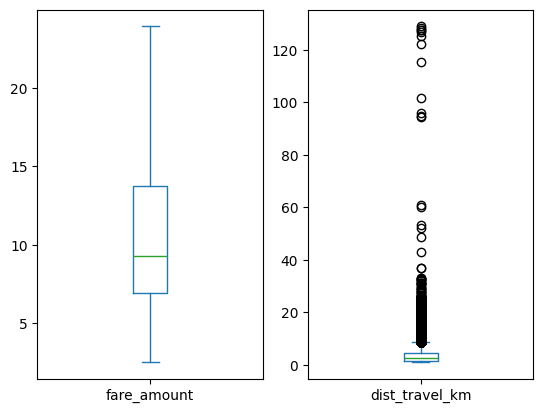

In [13]:
df[['fare_amount', 'dist_travel_km']].plot(
    kind='box', subplots=True
)
plt.show()

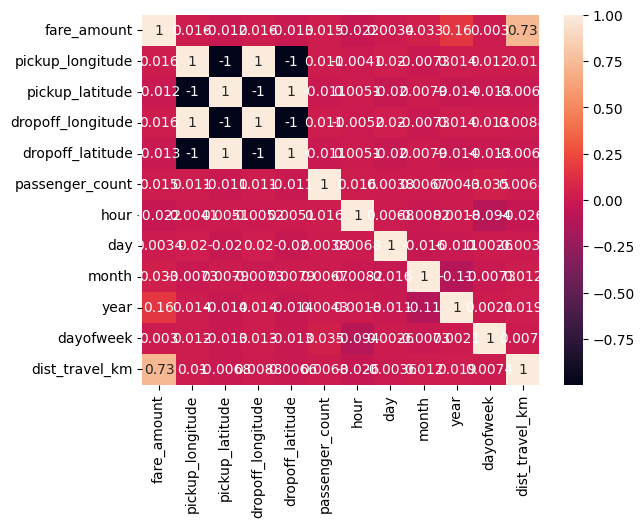

In [14]:
sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.show()

In [15]:
X = df.drop(['fare_amount'], axis=1)
y = df['fare_amount']

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [17]:
lr = LinearRegression()
lr.fit(X_train, y_train)
pred1 = lr.predict(X_test)

In [18]:
rf = RandomForestRegressor(
    n_estimators=100, random_state=42
)
rf.fit(X_train, y_train)
pred2 = rf.predict(X_test)


In [19]:
for name, pred in [('Linear Regression', pred1),
                   ('Random Forest', pred2)]:
    mse = mean_squared_error(y_test, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, pred)

    print(name)
    print("R2 Score:", r2)
    print("MSE:", mse)
    print("RMSE:", rmse)


Linear Regression
R2 Score: 0.5037214417725926
MSE: 16.012747917403605
RMSE: 4.001593172400663
Random Forest
R2 Score: 0.8468867071115096
MSE: 4.9402991952425275
RMSE: 2.222678383222037
